# LAB | Micromanage your agents

**Scenario:** you are building an evaluation system for **one specific use case**. Public benchmarks (like HLE in class) don't reflect your client's real questions, so you build **your own dataset**, upload it to LangSmith, run experiments and report what you found.

**How to use this notebook:**
- Cells marked **`# TODO`** are yours to complete. Replace every `...` with your code.
- **Hints** point to the lesson notebook (`02_langsmith(1).ipynb`), where you saw each idea.
- Markdown cells with a bold prompt (e.g. **Document your choice here:**, **Key findings:**) are for your written answers.
- Run the cells **in order**, top to bottom.

| Part | You will… | Concept from class |
|---|---|---|
| 1 | Choose a domain + set up LangSmith | Tracing, projects, regions |
| 2 | Build and upload your own dataset | Datasets: inputs, reference outputs, metadata |
| 3 | Write the target function + evaluators | Target, LLM-as-a-judge (OpenEvals), exact match |
| 4 | Run the experiment and review it in the UI | `client.evaluate()`, experiments, feedback |
| 5 | Analyse results + write `evaluation_summary.md` | Metrics, error analysis |
| Optional 1 | Design a custom evaluator | Judge prompt anatomy (notebook 01) |
| Optional 2 | A/B test models on cost vs performance | Model comparison, cost per correct answer |

In [1]:
%pip install langsmith openai openevals python-dotenv pandas matplotlib -q

Note: you may need to restart the kernel to use updated packages.


## Part 1: Setup & document selection (30–45 min)
### Step 1: Choose your domain and documents

Pick a domain where **you** can judge what a good answer looks like. Ideas: customer support FAQ, a company policy, a product catalogue, course material, a legal or compliance text, code review…

Each example needs:
- a clear **input** (question, ticket, task)
- ideally an **expected output** (reference answer, label, summary)
- enough **variety**: easy and hard cases, different categories

 **Hint:** the best datasets include **tricky cases**: questions with no answer in the document, ambiguous wording, multi-step questions. Easy-only datasets give 100% scores and teach you nothing (remember the calibration set in notebook 01, §6).

**Document your choice here:**

- **Domain:** Customer support for ShopCo, a fictional online store.
  The assistant answers questions about shipping and returns in English,
  using only the provided policy.

- **Source(s) of my documents:** `data/shopco_policy.md`, version 1.0.
  This fictional policy was created with AI assistance for this lab
  and reviewed by me.

- **What is one example? (input → expected output):**
  Input: the policy and the question “Can I return a sale item?”
  Expected output: “Yes. Sale items follow the same return rules
  as full-price items.”

- **What makes a good answer in my domain?**
  A good answer is correct, clear, and based only on the policy.
  It includes the conditions needed to answer the question.
  If information is missing from the policy, it refers the customer
  to support. If customer details are missing, it asks for clarification.
  It does not invent rules.

### Step 2: Set up LangSmith

 **Hint:** copy the setup pattern from `02_langsmith(1).ipynb` (Setup: keys and region). Your `.env` needs `LANGSMITH_API_KEY` and `OPENAI_API_KEY`. Check your **region**: `eu.smith.langchain.com` in the browser means EU.

In [1]:
import os
from dotenv import load_dotenv

load_dotenv(".env", override=True)

os.environ["LANGSMITH_TRACING"] = "true"

PROJECT_NAME = "lab-langsmith-shopco"
os.environ["LANGSMITH_PROJECT"] = PROJECT_NAME
os.environ["LANGSMITH_ENDPOINT"] = "https://eu.api.smith.langchain.com"

# Check that keys are loaded without displaying them
print("LangSmith key loaded:", bool(os.getenv("LANGSMITH_API_KEY")))
print("OpenAI key loaded:", bool(os.getenv("OPENAI_API_KEY")))
print("Project:", PROJECT_NAME)
print("Region: EU")

LangSmith key loaded: True
OpenAI key loaded: True
Project: lab-langsmith-shopco
Region: EU


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from langsmith import Client, traceable
from langsmith.wrappers import wrap_openai
from openai import OpenAI
from openevals.llm import create_llm_as_judge
from openevals.prompts import CORRECTNESS_PROMPT

OUT = Path("outputs")
OUT.mkdir(exist_ok=True)

client = Client()
openai_client = wrap_openai(OpenAI())

# Test the LangSmith connection
visible_datasets = list(client.list_datasets(limit=5))
print("LangSmith connection: OK")
print("Visible datasets (up to 5):", len(visible_datasets))

LangSmith connection: OK
Visible datasets (up to 5): 0


## Part 2: Dataset creation (60–90 min)
### Step 3: Extract and structure your examples

Turn your documents into a list of examples. Every example is a dictionary with the **same keys**.

| Field | Goes to | Example |
|---|---|---|
| `question` (+ `context` if RAG-style) | **inputs**: what the model sees | "Can I return a sale item?" |
| `answer` | **outputs**: the reference answer | "Yes, within 14 days, store credit only." |
| `category`, `difficulty`, `source` | **metadata**: for analysis, the model never sees it | "returns", "hard", "policy.pdf p.3" |

 **Hint:** aim for **15–20 examples** (minimum 10). Include at least 2 categories and at least 2 "hard" or "trap" examples.

In [4]:
# TODO: build your examples (by hand, or parse a CSV / JSON / text file)
# Option A: write them by hand
# Option B: load from a file
# examples = pd.read_csv("my_examples.csv").to_dict(orient="records")

policy_path = Path("data/shopco_policy.md")
policy_text = policy_path.read_text(encoding="utf-8")

print("Policy loaded:", policy_path.name)
print("Characters:", len(policy_text))
print(policy_text[:200])

# Draft reference answers: review each one against the policy.
cases = [
    # Shipping: 5 examples
    (
        "Where does ShopCo deliver?",
        "ShopCo delivers only to mainland Spain.",
        "shipping", "easy", "S1"
    ),
    (
        "How long does standard delivery take?",
        "Standard delivery takes 3–5 business days after dispatch.",
        "shipping", "easy", "S2"
    ),
    (
        "My order total is exactly €50. How much is shipping?",
        "Shipping is free for an order of exactly €50.",
        "shipping", "medium", "S3"
    ),
    (
        "How can I track my order?",
        "You receive a tracking link by email after dispatch.",
        "shipping", "easy", "S4"
    ),
    (
        "My order was dispatched 6 business days ago and has not arrived. What should I do?",
        "Contact customer support at support@shopco.example with your order number.",
        "shipping", "medium", "S5, C1"
    ),

    # Returns: 7 examples
    (
        "How long do I have to request a return?",
        "You can request a return within 30 calendar days of delivery.",
        "returns", "easy", "R1"
    ),
    (
        "What conditions apply to a change-of-mind return?",
        "Request the return within 30 calendar days of delivery. The product must be unused, in its original packaging, and accompanied by proof of purchase.",
        "returns", "medium", "R1, R2"
    ),
    (
        "My sale item arrived 10 calendar days ago. It is unused, in its original packaging, and I have proof of purchase. Can I return it because I changed my mind, and who pays return shipping?",
        "Yes. Sale items follow the same return rules. You meet the stated conditions, and you pay the return shipping cost.",
        "returns", "hard", "R1, R2, R3, R4"
    ),
    (
        "My unused product arrived 31 calendar days ago. Can I request a change-of-mind return?",
        "No. The policy allows return requests only within 30 calendar days of delivery.",
        "returns", "medium", "R1"
    ),
    (
        "My product arrived damaged. What should I do, and who pays return shipping?",
        "Contact support at support@shopco.example with your order number and a photo. ShopCo pays the return shipping cost.",
        "returns", "medium", "R5, C1"
    ),
    (
        "ShopCo sent me the wrong product. What should I provide to support?",
        "Contact support at support@shopco.example with your order number and a photo.",
        "returns", "easy", "R5, C1"
    ),
    (
        "I posted my return today. Will my refund arrive within 7 business days from today, and where will the money go?",
        "The 7-business-day period starts after ShopCo receives and approves the return, not when you post it. The refund goes to your original payment method.",
        "returns", "hard", "R6"
    ),

    # Missing information: 3 examples
    (
        "Can I pay with PayPal?",
        "The policy does not provide information about accepted payment methods. Contact support at support@shopco.example.",
        "missing_information", "hard", "C1, C2"
    ),
    (
        "Can I return my order?",
        "Please confirm when the order was delivered, the reason for the return, and the product's condition. For a change-of-mind return, also confirm whether you have the original packaging and proof of purchase before eligibility can be confirmed.",
        "missing_information", "hard", "R1, R2, C3"
    ),
    (
        "What is the exact return shipping cost for my eligible change-of-mind return?",
        "You pay the return shipping cost, but the policy does not specify the exact amount. Contact support at support@shopco.example.",
        "missing_information", "hard", "R4, C1, C2"
    ),
]

examples = [
    {
        "question": question,
        "context": policy_text,
        "answer": answer,
        "category": category,
        "difficulty": difficulty,
        "source": f"data/shopco_policy.md v1.0 — {rules}",
    }
    for question, answer, category, difficulty, rules in cases
]

print("Examples prepared:", len(examples))

display(
    pd.DataFrame(examples)[
        ["question", "answer", "category", "difficulty", "source"]
    ]
)

Policy loaded: shopco_policy.md
Characters: 1588
# ShopCo — Customer Support Policy
Version: 1.0

This is a fictional policy created for this learning exercise.
It does not describe a real company.

## Shipping
S1. ShopCo delivers only to mainland S
Examples prepared: 15


,question,answer,category,difficulty,source
0,Where does ShopCo deliver?,ShopCo delivers only to mainland Spain.,shipping,easy,data/shopco_policy.md v1.0 — S1
1,How long does standard delivery take?,Standard delivery takes 3–5 business days afte...,shipping,easy,data/shopco_policy.md v1.0 — S2
2,My order total is exactly €50. How much is shi...,Shipping is free for an order of exactly €50.,shipping,medium,data/shopco_policy.md v1.0 — S3
3,How can I track my order?,You receive a tracking link by email after dis...,shipping,easy,data/shopco_policy.md v1.0 — S4
4,My order was dispatched 6 business days ago an...,Contact customer support at support@shopco.exa...,shipping,medium,"data/shopco_policy.md v1.0 — S5, C1"
5,How long do I have to request a return?,You can request a return within 30 calendar da...,returns,easy,data/shopco_policy.md v1.0 — R1
6,What conditions apply to a change-of-mind return?,Request the return within 30 calendar days of ...,returns,medium,"data/shopco_policy.md v1.0 — R1, R2"
7,My sale item arrived 10 calendar days ago. It ...,Yes. Sale items follow the same return rules. ...,returns,hard,"data/shopco_policy.md v1.0 — R1, R2, R3, R4"
8,My unused product arrived 31 calendar days ago...,No. The policy allows return requests only wit...,returns,medium,data/shopco_policy.md v1.0 — R1
9,"My product arrived damaged. What should I do, ...",Contact support at support@shopco.example with...,returns,medium,"data/shopco_policy.md v1.0 — R5, C1"


In [5]:
for i, ex in enumerate(examples, start=1):
    print(f"\nEXAMPLE {i}")
    print("Question:", ex["question"])
    print("Reference answer:", ex["answer"])
    print("Source:", ex["source"])
    print("-" * 60)


EXAMPLE 1
Question: Where does ShopCo deliver?
Reference answer: ShopCo delivers only to mainland Spain.
Source: data/shopco_policy.md v1.0 — S1
------------------------------------------------------------

EXAMPLE 2
Question: How long does standard delivery take?
Reference answer: Standard delivery takes 3–5 business days after dispatch.
Source: data/shopco_policy.md v1.0 — S2
------------------------------------------------------------

EXAMPLE 3
Question: My order total is exactly €50. How much is shipping?
Reference answer: Shipping is free for an order of exactly €50.
Source: data/shopco_policy.md v1.0 — S3
------------------------------------------------------------

EXAMPLE 4
Question: How can I track my order?
Reference answer: You receive a tracking link by email after dispatch.
Source: data/shopco_policy.md v1.0 — S4
------------------------------------------------------------

EXAMPLE 5
Question: My order was dispatched 6 business days ago and has not arrived. What should I

In [6]:
# TODO: data quality checks
expected_keys = {
    "question", "context", "answer",
    "category", "difficulty", "source"
}

assert len(examples) >= 10, "At least 10 examples are required."

for i, ex in enumerate(examples, start=1):
    assert set(ex) == expected_keys, f"Example {i}: incorrect fields."

    for field in expected_keys:
        assert isinstance(ex[field], str) and ex[field].strip(), (
            f"Example {i}: empty or invalid '{field}'."
        )

    assert ex["context"] == policy_text, (
        f"Example {i}: context differs from the policy."
    )

questions = [ex["question"].strip().casefold() for ex in examples]
assert len(questions) == len(set(questions)), "Duplicate questions found."

examples_df = pd.DataFrame(examples)

assert examples_df["category"].nunique() >= 2
assert (examples_df["difficulty"] == "hard").sum() >= 2

print("Data quality checks: PASSED")
print("Total examples:", len(examples))

print("\nExamples by category:")
print(examples_df["category"].value_counts().to_string())

print("\nExamples by difficulty:")
print(examples_df["difficulty"].value_counts().to_string())

Data quality checks: PASSED
Total examples: 15

Examples by category:
category
returns                7
shipping               5
missing_information    3

Examples by difficulty:
difficulty
easy      5
medium    5
hard      5


**My data structure:**

Each example contains six fields:

- `question`: the customer's question in English.
- `context`: the full ShopCo policy, version 1.0.
- `answer`: the reference answer used for evaluation.
- `category`: shipping, returns, or missing_information.
- `difficulty`: easy, medium, or hard.
- `source`: the source file, version, and relevant policy rules.

The model receives only `question` and `context`.
The reference `answer` is used by the evaluator.
The remaining fields are metadata for analysis.

The dataset contains 15 examples across three categories,
with five examples per difficulty level. Questions and reference
answers were drafted with AI assistance and manually reviewed by me
against the policy. Automated checks confirmed consistent fields,
non-empty values, matching context, and no duplicate questions.

### Step 4: Create the LangSmith dataset

 **Hints (§2 of `02_langsmith(1).ipynb`):**
- Check `client.list_datasets()` first, so re-running the cell doesn't create a duplicate.
- `client.create_dataset(name, description=...)` then `client.create_examples(inputs=[...], outputs=[...], metadata=[...], dataset_id=...)`.
- Put a **version** in the name (e.g. `-v1`). If you change the examples later, create `-v2` instead of editing silently.

In [7]:
DATASET_NAME = "shopco-support-sandra-v1"
DATASET_DESCRIPTION = (
    "15 English customer-support examples based on the fictional "
    "ShopCo policy v1.0. Covers shipping, returns, and missing information. "
    "AI-assisted reference answers manually reviewed by Sandra."
)

existing = [d.name for d in client.list_datasets()]

if DATASET_NAME not in existing:
    dataset = client.create_dataset(
        dataset_name=DATASET_NAME,
        description=DATASET_DESCRIPTION,
    )

    client.create_examples(
        inputs=[
            {"question": ex["question"], "context": ex["context"]}
            for ex in examples
        ],
        outputs=[
            {"answer": ex["answer"]}
            for ex in examples
        ],
        metadata=[
            {
                "category": ex["category"],
                "difficulty": ex["difficulty"],
                "source": ex["source"],
            }
            for ex in examples
        ],
        dataset_id=dataset.id,
    )

    print(f"Created '{DATASET_NAME}'")
else:
    print(f"'{DATASET_NAME}' already exists; upload skipped.")

stored_examples = list(
    client.list_examples(dataset_name=DATASET_NAME)
)

print("Examples stored in LangSmith:", len(stored_examples))
assert len(stored_examples) == len(examples), (
    "The stored example count does not match the local dataset."
)
print("Dataset count check: PASSED")

Created 'shopco-support-sandra-v1'
Examples stored in LangSmith: 15
Dataset count check: PASSED


**Go and look:** open **Datasets → your dataset** in LangSmith. Are inputs, reference outputs and metadata all there? Take a **screenshot** for your repo.

**Dataset name + description:**

- Name: `shopco-support-sandra-v1`
- Description: 15 English customer-support examples based on
  the fictional ShopCo policy v1.0, covering shipping, returns,
  and missing information.
- Verification: all 15 examples were uploaded. Inputs, reference
  outputs, and metadata were checked in the LangSmith UI.
- Evidence: `outputs/dataset_shopco.png`

## Part 3: Evaluation setup (45–60 min)
### Step 5: Target function

The target is **the system under test**: it takes `inputs` from one example and returns `outputs`.

 **Hints (§3 of `02_langsmith(1).ipynb`):**
- Signature: `def target(inputs: dict) -> dict`, returning e.g. `{"answer": "..."}`.
- Add `@traceable` so the whole function (not only the OpenAI call) appears as one trace.
- Set `temperature=0` for controlled randomness (§5 Reproducibility: still not 100% guaranteed).
- **gpt-5 family:** use `max_completion_tokens` instead of `max_tokens`, and `reasoning_effort="none"` for short direct answers.
- **Error handling:** wrap the API call in `try/except` and return `{"answer": "", "error": str(e)}`, so one failure doesn't stop the whole experiment.

In [8]:
MODEL = "gpt-4o-mini"

SYSTEM_PROMPT = """
You are ShopCo's customer support assistant.

Answer the customer's question in clear, simple English.
Use only the provided policy and the customer's information.
Include all relevant conditions. Do not invent facts or rules.

If the policy does not contain the answer, say that the information
is not available and refer the customer to support@shopco.example.

If customer details are missing, ask for clarification before
confirming eligibility.

Be polite and concise. Write between 1 and 100 words.
Do not claim that you checked an order or processed a return.
"""

@traceable(name="shopco-support-target")
def target(inputs: dict) -> dict:
    """Answer a customer question using the supplied ShopCo policy."""
    try:
        response = openai_client.chat.completions.create(
            model=MODEL,
            temperature=0,
            max_tokens=250,
            messages=[
                {"role": "system", "content": SYSTEM_PROMPT},
                {
                    "role": "user",
                    "content": (
                        f"Policy:\n{inputs['context']}\n\n"
                        f"Customer question:\n{inputs['question']}"
                    ),
                },
            ],
        )

        answer = response.choices[0].message.content or ""
        return {"answer": answer.strip()}

    except Exception as e:
        return {
            "answer": "",
            "error": f"{type(e).__name__}: {e}",
        }

In [9]:
# TODO: test the target on 2-3 examples BEFORE running the full evaluation
# Test three different cases before the full experiment
test_indices = [0, 7, 12]
test_outputs = []

for index in test_indices:
    ex = examples[index]

    result = target({
        "question": ex["question"],
        "context": ex["context"],
    })

    test_outputs.append(result)

    print(f"\nEXAMPLE {index + 1}")
    print("Question:", ex["question"])
    print("Model answer:", result["answer"])

    if result.get("error"):
        print("Error:", result["error"])

    print("Reference answer:", ex["answer"])
    print("-" * 60)


EXAMPLE 1
Question: Where does ShopCo deliver?
Model answer: ShopCo delivers only to mainland Spain. If you have any further questions, feel free to ask!
Reference answer: ShopCo delivers only to mainland Spain.
------------------------------------------------------------

EXAMPLE 8
Question: My sale item arrived 10 calendar days ago. It is unused, in its original packaging, and I have proof of purchase. Can I return it because I changed my mind, and who pays return shipping?
Model answer: Yes, you can return the sale item since it is unused, in its original packaging, and you have proof of purchase. However, you will need to pay the return shipping cost. If you have any further questions, feel free to ask!
Reference answer: Yes. Sale items follow the same return rules. You meet the stated conditions, and you pay the return shipping cost.
------------------------------------------------------------

EXAMPLE 13
Question: Can I pay with PayPal?
Model answer: I'm sorry, but the informati

### Step 6: Evaluators

 **Hints:**
- Correctness: OpenEvals `CORRECTNESS_PROMPT` + `create_llm_as_judge(...)`, exactly as in §3 of `02_langsmith(1).ipynb`.
- Use a **different (stronger) model as judge** than the model under test.
- Exact match only makes sense when answers are short labels (a letter, a category, a number). For free-text answers, skip it or use a keyword check instead.
- An evaluator function returns a dict like `{"key": "my_metric", "score": True}`.

In [10]:
JUDGE_MODEL = "openai:gpt-5.4-mini"

_correctness_judge = create_llm_as_judge(
    prompt=CORRECTNESS_PROMPT,
    model=JUDGE_MODEL,
    feedback_key="correctness",
)

def correctness_evaluator(
    inputs: dict,
    outputs: dict,
    reference_outputs: dict,
) -> dict:
    """Compare the model answer with the reference answer."""
    if outputs.get("error") or not outputs.get("answer", "").strip():
        return {
            "key": "correctness",
            "score": False,
            "comment": "The target returned an error or an empty answer.",
        }

    return _correctness_judge(
        inputs=inputs,
        outputs={"answer": outputs["answer"]},
        reference_outputs=reference_outputs,
    )


def rule_evaluator(
    outputs: dict,
    reference_outputs: dict,
) -> dict:
    """Check response length only, not factual correctness."""
    answer = outputs.get("answer", "")
    word_count = len(answer.split())

    passed = (
        not outputs.get("error")
        and 1 <= word_count <= 100
    )

    return {
        "key": "response_length",
        "score": bool(passed),
        "comment": f"Word count: {word_count}. Required: 1–100.",
    }

In [11]:
ex = examples[0]

test_inputs = {
    "question": ex["question"],
    "context": ex["context"],
}
reference = {"answer": ex["answer"]}

test_answers = {
    "correct": {"answer": "ShopCo delivers only to mainland Spain."},
    "wrong": {"answer": "ShopCo delivers worldwide for free."},
}

for label, output in test_answers.items():
    print(f"\nTEST: {label}")
    print("Answer:", output["answer"])

    correctness = correctness_evaluator(
        inputs=test_inputs,
        outputs=output,
        reference_outputs=reference,
    )
    length = rule_evaluator(
        outputs=output,
        reference_outputs=reference,
    )

    print("Correctness:", correctness)
    print("Response length:", length)


TEST: correct
Answer: ShopCo delivers only to mainland Spain.
Correctness: {'key': 'correctness', 'score': True, 'comment': 'The response exactly matches the policy statement in the provided context: ShopCo delivers only to mainland Spain. It is accurate, complete for the question asked, and uses the correct terminology without adding unsupported information. Thus, the score should be: true.', 'metadata': None}
Response length: {'key': 'response_length', 'score': True, 'comment': 'Word count: 6. Required: 1–100.'}

TEST: wrong
Answer: ShopCo delivers worldwide for free.
Correctness: {'key': 'correctness', 'score': False, 'comment': 'The response is factually incorrect. The policy explicitly says ShopCo delivers only to mainland Spain, but the answer claims worldwide delivery and adds that it is free, which is also unsupported except for orders of €50 or more. It fails to answer the question accurately and invents incorrect information. Thus, the score should be: false.', 'metadata': N

**What does "correct" mean in my domain?**

There are many valid ways to write an answer. A correct answer must
follow the ShopCo policy, answer all parts of the question, and avoid
unsupported claims. It must ask for clarification or refer the customer
to support when appropriate.

- `correctness`: an LLM judge compares the answer with the reference,
  considering the question and policy. It evaluates meaning, not exact wording.
- `response_length`: a deterministic rule checks that the answer contains
  1–100 words and that the target did not return an error.
  It does not measure factual correctness.

Both evaluators were tested with one correct and one deliberately
incorrect answer. Correctness returned True and False respectively.
Both answers passed the length check, as expected.
This is a basic check, not a complete validation of the judge.

## Part 4: Run the evaluation (30–45 min)
### Step 7: Execute the experiment

 **Hint (§3 of `02_langsmith(1).ipynb`):** `client.evaluate(target, data=..., evaluators=[...], experiment_prefix=..., max_concurrency=2)`. Use a prefix that tells you **what** ran, e.g. `"gpt-4o-mini-promptv1"`.

In [12]:
# TODO: run the experiment
results = client.evaluate(
    target,
    data=DATASET_NAME,
    evaluators=[
        correctness_evaluator,
        rule_evaluator,
    ],
    experiment_prefix="shopco-gpt4o-mini-promptv1",
    max_concurrency=2,
)

print(results)

/opt/miniconda3/envs/bootcamp-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


View the evaluation results for experiment: 'shopco-gpt4o-mini-promptv1-6571eb9e' at:
https://eu.smith.langchain.com/o/17e08f1d-f35a-4236-b995-58ab83d3b83b/datasets/d2e58858-c5c6-4212-a8f5-1b48516a1f99/compare?selectedSessions=fe23cce8-fa82-47c2-bcfe-171917718478




15it [00:12,  1.21it/s]

<ExperimentResults shopco-gpt4o-mini-promptv1-6571eb9e>


In [13]:
# TODO: collect the results into a DataFrame and check that EVERY example was processed
df = results.to_pandas()

print("Processed examples:", len(df))
print("\nAvailable columns:")
print(df.columns.tolist())

assert len(df) == len(examples), "Some examples were not processed."

for metric in ["correctness", "response_length"]:
    column = f"feedback.{metric}"

    if column in df.columns:
        print(f"\n{metric}:")
        print("Scored examples:", df[column].notna().sum())
        print(df[column].value_counts(dropna=False).to_string())
    else:
        print(f"\nMissing score column: {column}")

df.to_csv(OUT / "results_main.csv", index=False)
print("\nSaved: outputs/results_main.csv")

Processed examples: 15

Available columns:
['inputs.context', 'inputs.question', 'outputs.answer', 'error', 'reference.answer', 'feedback.correctness', 'feedback.response_length', 'execution_time', 'example_id', 'id']

correctness:
Scored examples: 15
feedback.correctness
True     14
False     1

response_length:
Scored examples: 15
feedback.response_length
True    15

Saved: outputs/results_main.csv


### Step 8: Review the results in the LangSmith UI

**Go and look:** click the experiment link printed above.
- Open 2–3 **failed** examples and read the judge's reasoning (`comment`).
- Do the LLM judge and your rule-based evaluator **agree**? Look at the rows where they don't.
- Take **screenshots** (experiment table + one trace) for your repo.

**First observations + experiment link:**

All 15 examples received scores from both evaluators.
Correctness passed 14/15 cases (93.3%), and response length
passed 15/15 cases (100%).

The failed case was “Can I return my order?”. The model correctly
asked for clarification without confirming eligibility, but omitted
the return reason and proof of purchase. We classify this as
incomplete clarification, not hallucination.

The judge's comment was partly inaccurate: the model did ask about
original packaging. However, the other omissions support the failure
under our single-response completeness criterion. A conversation
could collect these details over several turns, which this test
does not evaluate.

The evaluators disagreed on this case because they measure different
properties: a short answer can still be incomplete.

Experiment:
https://eu.smith.langchain.com/o/17e08f1d-f35a-4236-b995-58ab83d3b83b/datasets/d2e58858-c5c6-4212-a8f5-1b48516a1f99/compare?selectedSessions=fe23cce8-fa82-47c2-bcfe-171917718478

Evidence:
- outputs/experiment_overview.png
- outputs/experiment_failed_case.png

## Part 5: Analysis & reporting (45–60 min)
### Step 9: Analyse results

In [14]:
# TODO: aggregate metrics for each evaluator: mean (= pass rate for True/False), n, number failed
#  True/False scores: .astype(float).mean() gives the pass rate
metric_rows = []

for metric in ["correctness", "response_length"]:
    scores = df[f"feedback.{metric}"].dropna().astype(float)

    metric_rows.append({
        "metric": metric,
        "total_examples": len(df),
        "scored": len(scores),
        "missing": len(df) - len(scores),
        "passed": int((scores == 1).sum()),
        "failed": int((scores == 0).sum()),
        "mean": scores.mean(),
        "median": scores.median(),
        "pass_rate_pct": scores.mean() * 100,
    })

metrics_summary = pd.DataFrame(metric_rows)

display(metrics_summary.round(2))

metrics_summary.to_csv(
    OUT / "metrics_summary.csv",
    index=False,
)

print("Saved: outputs/metrics_summary.csv")

,metric,total_examples,scored,missing,passed,failed,mean,median,pass_rate_pct
0,correctness,15,15,0,14,1,0.93,1.0,93.33
1,response_length,15,15,0,15,0,1.00,1.0,100.00


Saved: outputs/metrics_summary.csv


Results by category:


,total_examples,correctness_scored,correctness_pass_rate,length_scored,length_pass_rate
category,,,,,
missing_information,3,3,0.667,3,1.0
returns,7,7,1.000,7,1.0
shipping,5,5,1.000,5,1.0


Results by difficulty:


,total_examples,correctness_scored,correctness_pass_rate,length_scored,length_pass_rate
difficulty,,,,,
easy,5,5,1.0,5,1.0
medium,5,5,1.0,5,1.0
hard,5,5,0.8,5,1.0


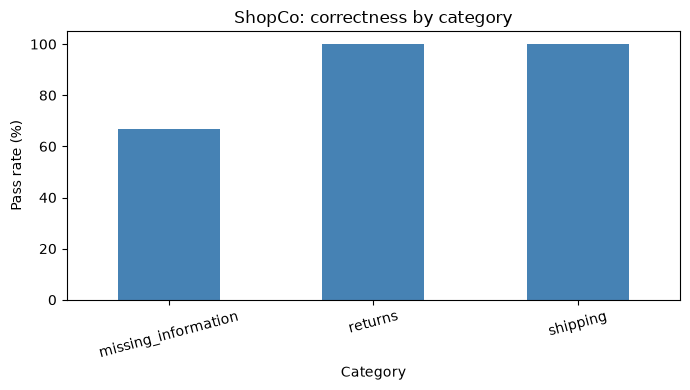

In [15]:
# TODO: performance by category and by difficulty
# The results DataFrame has no metadata, so join it from the dataset:
# Join results with dataset metadata
meta = pd.DataFrame([
    {
        "example_id": str(e.id),
        **(e.metadata or {}),
    }
    for e in client.list_examples(dataset_name=DATASET_NAME)
])

df["example_id"] = df["example_id"].astype(str)

# Remove previous metadata columns so the cell can be rerun safely
df = df.drop(
    columns=["category", "difficulty", "source"],
    errors="ignore",
)

df = df.merge(
    meta[["example_id", "category", "difficulty", "source"]],
    on="example_id",
    how="left",
    validate="many_to_one",
)

assert len(df) == len(examples)
assert df[["category", "difficulty", "source"]].notna().all().all()

# Calculate scores by category and difficulty
score_columns = [
    "feedback.correctness",
    "feedback.response_length",
]

for column in score_columns:
    df[column] = df[column].astype(float)

def summarize_groups(field):
    return df.groupby(field).agg(
        total_examples=("example_id", "size"),
        correctness_scored=("feedback.correctness", "count"),
        correctness_pass_rate=("feedback.correctness", "mean"),
        length_scored=("feedback.response_length", "count"),
        length_pass_rate=("feedback.response_length", "mean"),
    )

by_category = summarize_groups("category")
by_difficulty = summarize_groups("difficulty").reindex(
    ["easy", "medium", "hard"]
)

print("Results by category:")
display(by_category.round(3))

print("Results by difficulty:")
display(by_difficulty.round(3))

by_category.to_csv(OUT / "metrics_by_category.csv")
by_difficulty.to_csv(OUT / "metrics_by_difficulty.csv")
df.to_csv(OUT / "results_with_metadata.csv", index=False)

# Chart: correctness pass rate by category
ax = (
    by_category["correctness_pass_rate"] * 100
).plot.bar(
    figsize=(7, 4),
    color="steelblue",
)

ax.set_title("ShopCo: correctness by category")
ax.set_xlabel("Category")
ax.set_ylabel("Pass rate (%)")
ax.set_ylim(0, 105)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(OUT / "pass_rate_by_category.png", dpi=150)
plt.show()

In [16]:
# TODO: error analysis
# 1. Show every failed example: question, model answer, reference, judge comment
# 2. Give each failure a type by hand: wrong fact / incomplete / hallucination / wrong format / judge mistake / bad reference
# Show and document cases rejected by the correctness judge
failed_cases = df.loc[
    df["feedback.correctness"] == 0,
    [
        "example_id",
        "inputs.question",
        "outputs.answer",
        "reference.answer",
        "category",
        "difficulty",
    ],
].copy()

# Manual review of the observed failure
failed_cases["error_type"] = "pending_manual_review"
failed_cases["review_notes"] = ""

case_mask = (
    failed_cases["inputs.question"] == "Can I return my order?"
)

failed_cases.loc[case_mask, "error_type"] = "incomplete_clarification"
failed_cases.loc[case_mask, "review_notes"] = (
    "The model asked for delivery date, unused condition, and original "
    "packaging, but omitted return reason and proof of purchase. "
    "It did not confirm eligibility. The judge incorrectly suggested "
    "that packaging was also missing. The failure is retained under "
    "the single-response completeness criterion."
)

for _, row in failed_cases.iterrows():
    print("Question:", row["inputs.question"])
    print("Model answer:", row["outputs.answer"])
    print("Reference:", row["reference.answer"])
    print("Error type:", row["error_type"])
    print("Manual review:", row["review_notes"])
    print("-" * 60)

failed_cases.to_csv(OUT / "error_analysis.csv", index=False)
print("Saved: outputs/error_analysis.csv")

Question: Can I return my order?
Model answer: I need more information to confirm if you can return your order. Could you please provide the delivery date and whether the product is unused and in its original packaging?
Reference: Please confirm when the order was delivered, the reason for the return, and the product's condition. For a change-of-mind return, also confirm whether you have the original packaging and proof of purchase before eligibility can be confirmed.
Error type: incomplete_clarification
Manual review: The model asked for delivery date, unused condition, and original packaging, but omitted return reason and proof of purchase. It did not confirm eligibility. The judge incorrectly suggested that packaging was also missing. The failure is retained under the single-response completeness criterion.
------------------------------------------------------------
Saved: outputs/error_analysis.csv


**Key findings:**

1. **Overall pass rate per evaluator:**
   Correctness: 14/15 (93.3%).
   Response length: 15/15 (100%).
   Both evaluators scored all 15 examples.

2. **Performance by category and difficulty:**
   Shipping passed 5/5 and returns passed 7/7.
   Missing information passed 2/3 (66.7%).
   Easy and medium cases each passed 5/5; hard cases passed 4/5 (80%).
   These small groups do not establish general performance differences.

3. **Main observed failure:**
   For “Can I return my order?”, the model asked for some details
   but omitted the return reason and proof of purchase.
   This was incomplete clarification, not hallucination.
   The model did not confirm eligibility.

4. **Judge and reference review:**
   The judge incorrectly suggested that original packaging was missing
   from the model's question. The other omissions support keeping
   the failure under our single-response completeness criterion.
   No reference error was identified in this reviewed case.
   A multi-turn conversation could collect details gradually,
   but this experiment evaluates only one response.

5. **Limitations and recommendation:**
   This was one run on 15 fictional, English-only examples.
   One case changes the overall pass rate by about 6.7 percentage points.
   The length check does not measure factual correctness.
   We recommend adding an explicit clarification checklist to the prompt,
   then testing it on additional unseen ambiguous-return questions.

### Step 10: `evaluation_summary.md`

**One short paragraph** (plus optional bullets/table): what you evaluated, main metrics, biggest failure pattern, limitations, one recommendation. Not a long report.

In [17]:
# TODO: fill in and save. It goes at the ROOT of your repo.
summary = """# Evaluation summary

We evaluated ShopCo's customer-support assistant on 15 English examples
based on a fictional policy, with manually reviewed reference answers.
The dataset covers shipping, returns, and missing information.
The target used gpt-4o-mini with temperature=0 and max_tokens=250.
OpenEvals correctness, judged by gpt-5.4-mini, passed 14/15 cases
(93.3%); the 1–100-word rule passed 15/15 (100%), with no missing scores.
Shipping and returns passed all cases, while missing information passed
2/3. The only rejected answer asked for clarification but omitted the
return reason and proof of purchase. The judge also made a comment error:
the model did ask about original packaging. We kept the original score
under the single-response completeness criterion. This small, fictional,
English-only dataset and single run do not establish production reliability
or multi-turn performance; the length rule does not measure correctness.
We recommend adding a clarification checklist and testing it on new
ambiguous-return cases.

| Metric | Passed / Scored | Pass rate |
|---|---|---|
| Correctness (LLM judge) | 14/15 | 93.3% |
| Response length | 15/15 | 100% |

## Evidence

- [Results](outputs/results_main.csv)
- [Metrics](outputs/metrics_summary.csv)
- [Error analysis](outputs/error_analysis.csv)
- [Category chart](outputs/pass_rate_by_category.png)
- [Experiment screenshot](outputs/experiment_overview.png)

## LangSmith experiment

https://eu.smith.langchain.com/o/17e08f1d-f35a-4236-b995-58ab83d3b83b/datasets/d2e58858-c5c6-4212-a8f5-1b48516a1f99/compare?selectedSessions=fe23cce8-fa82-47c2-bcfe-171917718478
"""

# Keep the narrative as one paragraph
summary = summary.replace(
    summary.split("\n\n")[1],
    " ".join(summary.split("\n\n")[1].splitlines()),
)

summary_path = Path("evaluation_summary.md")
summary_path.write_text(summary, encoding="utf-8")

print("Saved:", summary_path.resolve())

Saved: /Users/sandraobregon/Desktop/Weekseven/day4/lab-langsmith/evaluation_summary.md


In [18]:
import json

dataset_path = Path("data/shopco_examples_v1.json")
dataset_path.write_text(
    json.dumps(examples, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print("Dataset saved:", dataset_path)
print("Examples:", len(examples))

Dataset saved: data/shopco_examples_v1.json
Examples: 15


In [19]:
required_files = [
    "02_langsmith.ipynb",
    "README.md",
    "lab_proof.md",
    "evaluation_summary.md",
    ".env.example",
    ".gitignore",
    "data/shopco_policy.md",
    "data/shopco_examples_v1.json",
    "outputs/results_main.csv",
    "outputs/results_with_metadata.csv",
    "outputs/metrics_summary.csv",
    "outputs/metrics_by_category.csv",
    "outputs/metrics_by_difficulty.csv",
    "outputs/error_analysis.csv",
    "outputs/pass_rate_by_category.png",
    "outputs/dataset_shopco.png",
    "outputs/target_trace_shopco.png",
    "outputs/experiment_failed_case.png",
    "outputs/experiment_overview.png",
]

missing = []

for name in required_files:
    exists = Path(name).is_file()
    print(f"{'OK' if exists else 'MISSING'}: {name}")
    if not exists:
        missing.append(name)

print("\nMissing files:", len(missing))

OK: 02_langsmith.ipynb
OK: README.md
OK: lab_proof.md
OK: evaluation_summary.md
OK: .env.example
OK: .gitignore
OK: data/shopco_policy.md
OK: data/shopco_examples_v1.json
OK: outputs/results_main.csv
OK: outputs/results_with_metadata.csv
OK: outputs/metrics_summary.csv
OK: outputs/metrics_by_category.csv
OK: outputs/metrics_by_difficulty.csv
OK: outputs/error_analysis.csv
OK: outputs/pass_rate_by_category.png
OK: outputs/dataset_shopco.png
OK: outputs/target_trace_shopco.png
OK: outputs/experiment_failed_case.png
OK: outputs/experiment_overview.png

Missing files: 0


---
## Optional Part 1: Custom evaluator (60–90 min)
### Step 11: Design it

Pick **one** dimension beyond correctness that matters for your domain: tone, completeness, groundedness in the context, safety / policy compliance, format…

 **Hints:**
- Use the 4-part judge prompt anatomy from notebook 01, §3: task, what you're given, criteria, reasoning steps + output format.
- Your prompt's `{variables}` must match the keyword arguments you pass (`inputs`, `outputs`, `reference_outputs`, or your own like `context`).
- Prebuilt prompts you can adapt: `RAG_GROUNDEDNESS_PROMPT`, `ANSWER_RELEVANCE_PROMPT`, `CONCISENESS_PROMPT`, `TOXICITY_PROMPT` (`print()` one to see how it's written).
- For a 1–5 scale instead of True/False: `create_llm_as_judge(..., continuous=True)` gives a 0–1 score, or `choices=[1, 2, 3, 4, 5]`.

**Not completed:** optional custom evaluator.
No custom-evaluator experiment was run.

### Step 12: Run it next to correctness

**Not completed:** optional custom evaluator.
No custom-evaluator experiment was run.

### Step 13:  Document your custom evaluator
**Not completed:** optional custom evaluator.
No custom-evaluator experiment was run.

---
## Optional Part 2: Cost & performance (60–90 min)
### Step 14: A/B comparison

 **Hints (§4 of `02_langsmith(1).ipynb`):**
- Same dataset, same evaluators, **only one thing changes** (the model, or the temperature, or the prompt).
- To get token usage, also return it from the target: `{"answer": ..., "prompt_tokens": r.usage.prompt_tokens, "completion_tokens": r.usage.completion_tokens}`.
- Latency: look for an `execution_time` column in `results.to_pandas()`.
- Fill `PRICES` from the **OpenAI pricing page** (USD per 1M tokens). Write down the date you checked it.

**Not completed:** optional cost and performance comparison.
No A/B experiment or optimization analysis was run.

### Step 15: Cost vs performance

**Not completed:** optional cost and performance comparison.
No A/B experiment or optimization analysis was run.

 **Before you recommend, think:**
- Is the gap between models bigger than **one or two examples**? With ~20 examples it may be luck (W7/D5).
- Which pass rate is **good enough** for this use case? A cheaper model that meets that bar wins.

### Step 16: `optimization_summary.md`

**Not completed:** optional cost and performance comparison.
No A/B experiment or optimization analysis was run.

---
## Reflection (optional, recommended)
1. What surprised you when you read the failed traces?
2. Did you trust your LLM judge? How did you check it?
3. What would you change in your dataset for a `-v2`?

## Submission checklist
- [ ] GitHub repo with **only** this lab, and a `README.md` (domain + dataset, approach, how to run, LangSmith links, file map)
- [ ] `lab_proof.md` as the **entry point**: code/workflow, one run with its input, the evidence it produced (trace / screenshot), the final output, and one failure or limitation you hit
- [ ] `evaluation_summary.md` at the repo root (one paragraph + optional table)
- [ ] (Optional) `optimization_summary.md` at the repo root
- [ ] Notebook runs top to bottom without errors; descriptive file names (no `lab.ipynb`, `final_v2.py`)
- [ ] `outputs/`: results CSV(s), charts, and LangSmith screenshots (dataset, experiment, one trace)
- [ ] **No API keys** in the repo: `.env` is in `.gitignore`